# Heart Disease Prediction — Step 4: Model Training

We train 4 models with their **default settings** first (no tuning yet — that's the next notebook),
and compare how they perform. This gives us an honest baseline before we spend time optimizing anything.

**Models:** Logistic Regression, Decision Tree, Random Forest, XGBoost

In [1]:
%pip install xgboost shap optuna joblib scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 1. Load the prepared data

Logistic Regression is sensitive to feature scale, so it uses the **scaled** data. The tree-based
models (Decision Tree, Random Forest, XGBoost) don't need scaling — they split on raw values either
way — so they use the **unscaled** data.

In [3]:
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')
X_train_scaled = pd.read_csv('X_train_scaled.csv')
X_test_scaled = pd.read_csv('X_test_scaled.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (715, 13)  Test: (179, 13)


## 2. Define the models

All four with default settings for now — we're establishing a fair baseline before tuning anything.

In [4]:
models = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
}

# Which data each model trains/tests on
uses_scaled = {'Logistic Regression'}

## 3. Train each model and collect predictions

In [5]:
results = {}
predictions = {}

for name, model in models.items():
    if name in uses_scaled:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    y_proba = model.predict_proba(Xte)[:, 1]

    predictions[name] = (y_pred, y_proba)

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba),
    }

print("All models trained.")

All models trained.


## 4. Compare results

All 5 metrics, side by side, for all 4 models.

In [6]:
results_df = pd.DataFrame(results).T.round(3)
results_df = results_df.sort_values('F1-score', ascending=False)
results_df

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Decision Tree,0.754,0.727,0.709,0.718,0.749
Random Forest,0.760,0.750,0.684,0.715,0.846
XGBoost,0.732,0.701,0.684,0.692,0.813
Logistic Regression,0.715,0.700,0.620,0.658,0.743


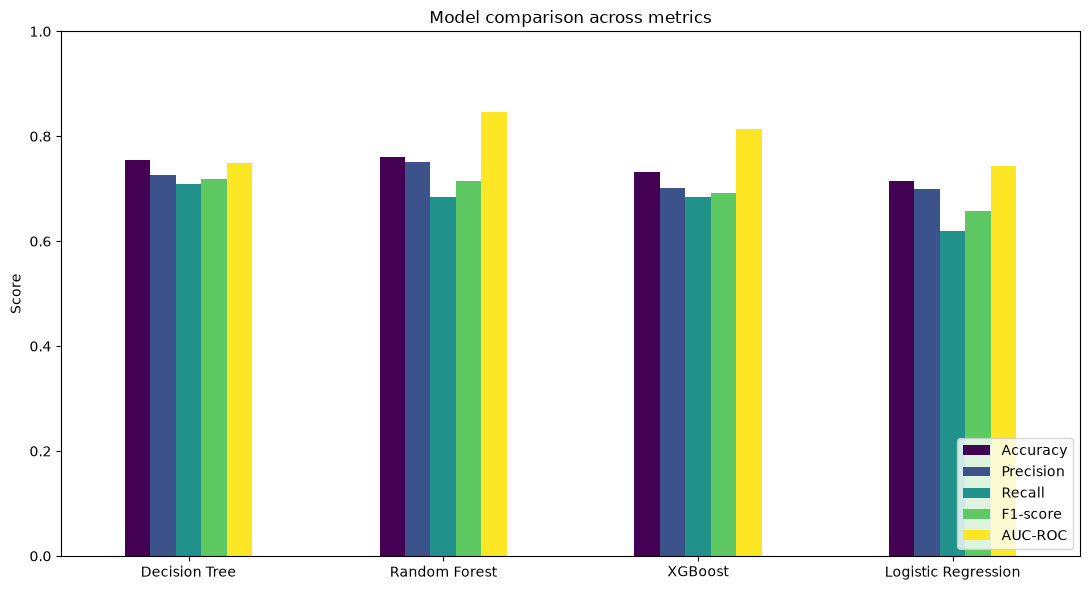

In [7]:
results_df.plot(kind='bar', figsize=(11, 6), colormap='viridis')
plt.title('Model comparison across metrics')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**How to read this:** every bar closer to 1.0 is better. No single metric tells the whole story —
that's exactly why we're looking at all 5 together rather than just picking the model with the highest
accuracy.

## 5. Confusion matrices

A confusion matrix breaks predictions into 4 outcomes:
- **True Negative** (top-left): correctly said "no disease"
- **False Positive** (top-right): wrongly said "disease" when there wasn't one
- **False Negative** (bottom-left): wrongly said "no disease" when there was one — **the most costly
  mistake in a medical context**, since a sick patient goes undetected
- **True Positive** (bottom-right): correctly said "disease"

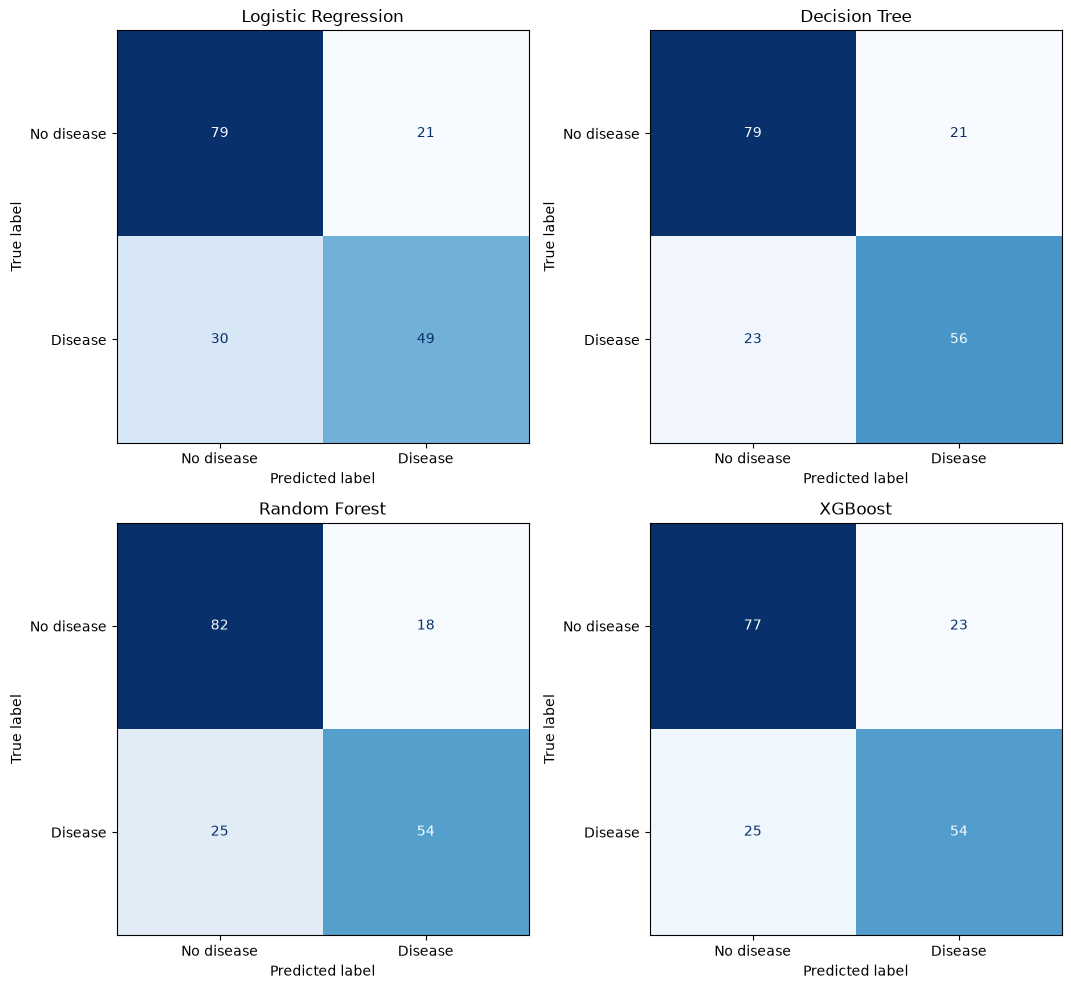

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.flatten()

for ax, (name, (y_pred, _)) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No disease', 'Disease'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 6. What do we do with these results?

We use this comparison to decide which model(s) to carry forward into the next stages
(hyperparameter tuning → SHAP explainability → web app). Carrying all 4 through every remaining stage
would use up time we don't have before the end of September, so we narrow down here.

In [9]:
print("Ranked by F1-score (balances precision and recall):")
print(results_df)
print()
best_model = results_df.index[0]
print(f"Best baseline model: {best_model}")

Ranked by F1-score (balances precision and recall):
                     Accuracy  Precision  Recall  F1-score  AUC-ROC
Decision Tree           0.754      0.727   0.709     0.718    0.749
Random Forest           0.760      0.750   0.684     0.715    0.846
XGBoost                 0.732      0.701   0.684     0.692    0.813
Logistic Regression     0.715      0.700   0.620     0.658    0.743

Best baseline model: Decision Tree


## Summary

- All 4 models trained on identical train/test splits, evaluated on the same held-out test set
- Comparison covers accuracy, precision, recall, F1-score, and AUC-ROC — not just accuracy alone,
  since recall matters a lot in a medical context (missing a sick patient is the costly mistake)
- These are **baseline** results with default settings — the next step, hyperparameter tuning, may
  change the ranking

Next step: **hyperparameter tuning** on the top-performing model(s), to see how much we can improve
on this baseline.